# Red neuronal de compuertas logicas

In [ ]:
import numpy as np

x = np.array([[0, 0], [0,1], [1,0], [1,1]])
y = np.array([0, 0, 0, 1])

print(x, " ", y)

[[0 0]
 [0 1]
 [1 0]
 [1 1]]   [0 0 0 1]


In [ ]:

import time
import numpy as np

def funcion_activacion(x):
    return 1 if x >= 0 else 0

def entrenar_neurona(X, y, tasa_aprendizaje=0.1, epocas=100):
    n_caracteristicas = X.shape[1]
    pesos = np.zeros(n_caracteristicas)
    bias = 0

    for ep in range(epocas):
        print(f"Epoca: ", ep)
        pesos_actualizados = False

        for i in range(X.shape[0]):
            z = np.dot(pesos, X[i]) + bias
            y_pred = funcion_activacion(z)
            error = y[i] - y_pred

            if error != 0:
                pesos += tasa_aprendizaje * error * X[i]
                bias += tasa_aprendizaje * error
                pesos_actualizados = True

        if not pesos_actualizados:
            break

    return pesos, bias

def predecir(input_1, input_2, pesos, bias):
    X_input = np.array([input_1, input_2])
    z = np.dot(pesos, X_input) + bias
    return funcion_activacion(z)

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 0, 0, 1])

pesos, bias = entrenar_neurona(X, y)
print("Pesos finales:", pesos)
print("Bias final:", bias)

clase = predecir(1, 1, pesos, bias)
print("Clase:", clase)

Epoca:  0
Epoca:  1
Epoca:  2
Epoca:  3
Pesos finales: [0.2 0.1]
Bias final: -0.20000000000000004
Clase: 1


In [ ]:
clase = predecir(1, 1, pesos, bias)
print("Clase:", clase)

Clase: 1


# Datos para la tarea de clasificación de especies de iris

In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

In [2]:
iris = pd.read_csv("/content/Iris.csv")
iris.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
iris["Species"].unique()

array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)

In [4]:
iris = iris[(iris['Species'] == 'Iris-versicolor') | (iris['Species'] == 'Iris-virginica')]

label_encoder = LabelEncoder()
iris['Species_encoded'] = label_encoder.fit_transform(iris['Species'])

iris.drop(columns=["Species", "Id"], inplace=True)

columnas = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']

scaler = MinMaxScaler()

iris[columnas] = scaler.fit_transform(iris[columnas])

datos = iris.drop(columns=["Species_encoded"])
etiquetas = iris["Species_encoded"]

X_train, X_test, y_train, y_test = train_test_split(datos, etiquetas, test_size=0.2, random_state=42)

<ipython-input-4-dbf0cc6936c6>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iris['Species_encoded'] = label_encoder.fit_transform(iris['Species'])
<ipython-input-4-dbf0cc6936c6>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iris.drop(columns=["Species", "Id"], inplace=True)
<ipython-input-4-dbf0cc6936c6>:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.

In [5]:
datos.info()
y_test.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 100 entries, 50 to 149
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  100 non-null    float64
 1   SepalWidthCm   100 non-null    float64
 2   PetalLengthCm  100 non-null    float64
 3   PetalWidthCm   100 non-null    float64
dtypes: float64(4)
memory usage: 3.9 KB


,Species_encoded
count,20.000000
mean,0.400000
std,0.502625
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


# Neurona inidividual para clasificacion lineal

In [6]:
def funcion_activacion(x):
    return 1 if x >= 0 else 0

def entrenar_neurona(X, y, tasa_aprendizaje=0.1, epocas=100):
    n_caracteristicas = X.shape[1]
    pesos = np.zeros(n_caracteristicas)
    bias = 0

    for ep in range(epocas):
        print(f"Epoca: ", ep)
        pesos_actualizados = False

        X_array = X.to_numpy()
        y_array = y.to_numpy()
        for i in range(X_array.shape[0]):
            z = np.dot(pesos, X_array[i]) + bias
            y_pred = funcion_activacion(z)
            error = y_array[i] - y_pred

            if error != 0:
                pesos += tasa_aprendizaje * error * X_array[i]
                bias += tasa_aprendizaje * error
                pesos_actualizados = True

        if not pesos_actualizados:
            break

    return pesos, bias

pesos, bias = entrenar_neurona(datos, etiquetas)
print("Pesos finales:", pesos)
print("Bias final:", bias)

Epoca:  0
Epoca:  1
Epoca:  2
Epoca:  3
Epoca:  4
Epoca:  5
Epoca:  6
Epoca:  7
Epoca:  8
Epoca:  9
Epoca:  10
Epoca:  11
Epoca:  12
Epoca:  13
Epoca:  14
Epoca:  15
Epoca:  16
Epoca:  17
Epoca:  18
Epoca:  19
Epoca:  20
Epoca:  21
Epoca:  22
Epoca:  23
Epoca:  24
Epoca:  25
Epoca:  26
Epoca:  27
Epoca:  28
Epoca:  29
Epoca:  30
Epoca:  31
Epoca:  32
Epoca:  33
Epoca:  34
Epoca:  35
Epoca:  36
Epoca:  37
Epoca:  38
Epoca:  39
Epoca:  40
Epoca:  41
Epoca:  42
Epoca:  43
Epoca:  44
Epoca:  45
Epoca:  46
Epoca:  47
Epoca:  48
Epoca:  49
Epoca:  50
Epoca:  51
Epoca:  52
Epoca:  53
Epoca:  54
Epoca:  55
Epoca:  56
Epoca:  57
Epoca:  58
Epoca:  59
Epoca:  60
Epoca:  61
Epoca:  62
Epoca:  63
Epoca:  64
Epoca:  65
Epoca:  66
Epoca:  67
Epoca:  68
Epoca:  69
Epoca:  70
Epoca:  71
Epoca:  72
Epoca:  73
Epoca:  74
Epoca:  75
Epoca:  76
Epoca:  77
Epoca:  78
Epoca:  79
Epoca:  80
Epoca:  81
Epoca:  82
Epoca:  83
Epoca:  84
Epoca:  85
Epoca:  86
Epoca:  87
Epoca:  88
Epoca:  89
Epoca:  90
Epoca:  9

In [7]:
def predecir(X_input, pesos, bias):
    z = np.dot(pesos, X_input) + bias
    return funcion_activacion(z)

In [8]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X_test_array = X_test.to_numpy()
y_pred = [predecir(x, pesos, bias) for x in X_test_array]


accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"Precisión del modelo: {accuracy:.4f}")
print("\nReporte de clasificación:")
print(report)
print("\nMatriz de confusión:")
print(conf_matrix)

Precisión del modelo: 0.8500

Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      0.75      0.86        12
           1       0.73      1.00      0.84         8

    accuracy                           0.85        20
   macro avg       0.86      0.88      0.85        20
weighted avg       0.89      0.85      0.85        20


Matriz de confusión:
[[9 3]
 [0 8]]


# Modelo Lineal multiclase

In [ ]:
import numpy as np

# Función de activación softmax
def softmax(z):
    exp_z = np.exp(z - np.max(z))  # Para evitar problemas de desbordamiento numérico
    return exp_z / np.sum(exp_z)

# Función de entrenamiento para clasificación multiclase (One-vs-All)
def entrenar_neurona_multiclase(X, y, tasa_aprendizaje=0.1, epocas=100, n_clases=None):
    n_caracteristicas = X.shape[1]
    if n_clases is None:
        n_clases = len(np.unique(y))  # Si no se especifica, inferimos el número de clases desde 'y'

    # Inicializamos los pesos y el bias para cada clase
    pesos = np.zeros((n_clases, n_caracteristicas))
    bias = np.zeros(n_clases)

    for ep in range(epocas):
        print(f"Epoca: ", ep)
        pesos_actualizados = False

        X_array = X.to_numpy()
        y_array = y.to_numpy()
        for i in range(X_array.shape[0]):
            # Realizamos la predicción para cada clase usando softmax
            z = np.dot(pesos, X_array[i]) + bias
            y_pred = softmax(z)

            # Convertimos la etiqueta en un vector de 'one-hot' para la clase correcta
            y_one_hot = np.zeros(n_clases)
            y_one_hot[y_array[i]] = 1  # Asumimos que las etiquetas son enteros (0, 1, 2, ..., n_clases-1)

            # Calculamos el error
            error = y_one_hot - y_pred

            # Actualizamos pesos y bias para cada clase
            for j in range(n_clases):
                if error[j] != 0:
                    pesos[j] += tasa_aprendizaje * error[j] * X_array[i]
                    bias[j] += tasa_aprendizaje * error[j]
                    pesos_actualizados = True

        if not pesos_actualizados:
            break

    return pesos, bias

# Función para predecir la clase
def predecir(X, pesos, bias):
    X_array = X.to_numpy()
    predicciones = []
    for i in range(X_array.shape[0]):
        z = np.dot(pesos, X_array[i]) + bias
        y_pred = softmax(z)
        predicciones.append(np.argmax(y_pred))  # La clase con la mayor probabilidad
    return np.array(predicciones)

# Ejemplo de uso
# Entrenamos el modelo
pesos, bias = entrenar_neurona_multiclase(X_train, y_train)

# Realizamos las predicciones
predicciones = predecir(X_test, pesos, bias)
print("Predicciones:", predicciones)
print("Etiquetas reales:", y_test.to_numpy())

Epoca:  0
Epoca:  1
Epoca:  2
Epoca:  3
Epoca:  4
Epoca:  5
Epoca:  6
Epoca:  7
Epoca:  8
Epoca:  9
Epoca:  10
Epoca:  11
Epoca:  12
Epoca:  13
Epoca:  14
Epoca:  15
Epoca:  16
Epoca:  17
Epoca:  18
Epoca:  19
Epoca:  20
Epoca:  21
Epoca:  22
Epoca:  23
Epoca:  24
Epoca:  25
Epoca:  26
Epoca:  27
Epoca:  28
Epoca:  29
Epoca:  30
Epoca:  31
Epoca:  32
Epoca:  33
Epoca:  34
Epoca:  35
Epoca:  36
Epoca:  37
Epoca:  38
Epoca:  39
Epoca:  40
Epoca:  41
Epoca:  42
Epoca:  43
Epoca:  44
Epoca:  45
Epoca:  46
Epoca:  47
Epoca:  48
Epoca:  49
Epoca:  50
Epoca:  51
Epoca:  52
Epoca:  53
Epoca:  54
Epoca:  55
Epoca:  56
Epoca:  57
Epoca:  58
Epoca:  59
Epoca:  60
Epoca:  61
Epoca:  62
Epoca:  63
Epoca:  64
Epoca:  65
Epoca:  66
Epoca:  67
Epoca:  68
Epoca:  69
Epoca:  70
Epoca:  71
Epoca:  72
Epoca:  73
Epoca:  74
Epoca:  75
Epoca:  76
Epoca:  77
Epoca:  78
Epoca:  79
Epoca:  80
Epoca:  81
Epoca:  82
Epoca:  83
Epoca:  84
Epoca:  85
Epoca:  86
Epoca:  87
Epoca:  88
Epoca:  89
Epoca:  90
Epoca:  9

# Red neuronal profunda

In [ ]:
import numpy as np

# -------------------- FUNCIONES DE ACTIVACIÓN --------------------
def relu(x):
    return np.maximum(0, x)

def relu_deriv(x):
    return (x > 0).astype(float)

def softmax(z):
    exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

def one_hot_encode(y, n_classes):
    y_one_hot = np.zeros((len(y), n_classes))
    y_one_hot[np.arange(len(y)), y] = 1
    return y_one_hot

# -------------------- INICIALIZACIÓN --------------------
def inicializar_red(n_entradas, capas_ocultas, n_clases):
    capas = []
    input_dim = n_entradas

    for n_neuronas in capas_ocultas:
        capa = {
            'W': np.random.randn(input_dim, n_neuronas) * np.sqrt(2. / input_dim),
            'b': np.zeros((1, n_neuronas)),
            'm_W': 0, 'v_W': 0,
            'm_b': 0, 'v_b': 0
        }
        capas.append(capa)
        input_dim = n_neuronas

    capa_salida = {
        'W': np.random.randn(input_dim, n_clases) * np.sqrt(2. / input_dim),
        'b': np.zeros((1, n_clases)),
        'm_W': 0, 'v_W': 0,
        'm_b': 0, 'v_b': 0
    }
    capas.append(capa_salida)

    return capas

# -------------------- FORWARD --------------------
def forward_propagation(X, capas):
    activaciones = [X]
    zetas = []

    for i, capa in enumerate(capas):
        z = np.dot(activaciones[-1], capa['W']) + capa['b']
        zetas.append(z)

        if i < len(capas) - 1:
            a = relu(z)
        else:
            a = softmax(z)

        activaciones.append(a)

    return activaciones, zetas

# -------------------- ADAM OPTIMIZER --------------------
def adam_update(param, grad, m, v, t, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
    m = beta1 * m + (1 - beta1) * grad
    v = beta2 * v + (1 - beta2) * (grad ** 2)

    m_hat = m / (1 - beta1 ** t)
    v_hat = v / (1 - beta2 ** t)

    param -= lr * m_hat / (np.sqrt(v_hat) + eps)
    return param, m, v

# -------------------- BACKPROPAGATION --------------------
def backpropagation(activaciones, zetas, y_true, capas, t, lr, l2_lambda):
    m = y_true.shape[0]
    y_pred = activaciones[-1]
    delta = y_pred - y_true

    for i in reversed(range(len(capas))):
        a_prev = activaciones[i]
        z = zetas[i]
        W = capas[i]['W']

        dW = (np.dot(a_prev.T, delta) / m) + l2_lambda * W
        db = np.sum(delta, axis=0, keepdims=True) / m

        # Adam updates
        W_new, m_W, v_W = adam_update(W, dW, capas[i]['m_W'], capas[i]['v_W'], t, lr)
        b_new, m_b, v_b = adam_update(capas[i]['b'], db, capas[i]['m_b'], capas[i]['v_b'], t, lr)

        capas[i]['W'], capas[i]['m_W'], capas[i]['v_W'] = W_new, m_W, v_W
        capas[i]['b'], capas[i]['m_b'], capas[i]['v_b'] = b_new, m_b, v_b

        if i > 0:
            delta = np.dot(delta, W.T) * relu_deriv(zetas[i - 1])

    return capas

# -------------------- ENTRENAMIENTO --------------------
def entrenar_red(X, y, n_clases, capas_ocultas, X_test, y_test, epocas=1000, lr=0.01, l2_lambda=0.01):
    X_np = X.to_numpy()
    y_np = y.to_numpy()
    y_one_hot = one_hot_encode(y_np, n_clases)

    capas = inicializar_red(X_np.shape[1], capas_ocultas, n_clases)
    historial_perdida = []
    historial_precision_train = []  # Historial de precisión en entrenamiento
    historial_precision_test = []   # Historial de precisión en test
    historial_recall = []
    historial_f1 = []

    for ep in range(1, epocas + 1):
        activaciones, zetas = forward_propagation(X_np, capas)
        capas = backpropagation(activaciones, zetas, y_one_hot, capas, ep, lr, l2_lambda)

        # Calcular pérdida total
        loss = -np.mean(np.sum(y_one_hot * np.log(activaciones[-1] + 1e-8), axis=1))
        reg_term = sum(np.sum(c['W'] ** 2) for c in capas) * l2_lambda / 2
        perdida_total = loss + reg_term

        # Predicciones para el conjunto de test
        y_pred_test = predecir(X_test, capas)

        # Calcular métricas de Precision, Recall, F1 para el conjunto de test
        precision_test = precision_score(y_test, y_pred_test, average='weighted', zero_division=1)
        #recall_test = recall_score(y_test, y_pred_test, average='weighted', zero_division=1)
        #f1_test = f1_score(y_test, y_pred_test, average='weighted', zero_division=1)

        # Predicciones para el conjunto de entrenamiento
        y_pred_train = predecir(X, capas)

        # Calcular precisión de entrenamiento
        precision_train = precision_score(y, y_pred_train, average='weighted', zero_division=1)

        # Guardar las métricas y la pérdida
        historial_perdida.append(perdida_total)
        historial_precision_train.append(precision_train)
        historial_precision_test.append(precision_test)
        #historial_recall.append(recall_test)
        #historial_f1.append(f1_test)

        if ep % 100 == 0 or ep == 1:
            print(f"Época {ep} - Pérdida: {perdida_total:.4f}, Precision Train: {precision_train:.4f}, Precision Test: {precision_test:.4f}")
            #, Recall: {recall_test:.4f}, F1: {f1_test:.4f}

    return capas, historial_perdida, historial_precision_train, historial_precision_test#, historial_recall, historial_f1



# -------------------- PREDICCIÓN --------------------
def predecir(X, capas):
    X_np = X.to_numpy()
    activaciones, _ = forward_propagation(X_np, capas)
    return np.argmax(activaciones[-1], axis=1)


Época 1 - Pérdida: 1.3640, Precision Train: 0.7751, Precision Test: 0.7900
Época 100 - Pérdida: 0.3338, Precision Train: 0.9675, Precision Test: 0.9694
Predicciones: [1 0 2 1 1 0 1 2 2 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Etiquetas reales: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


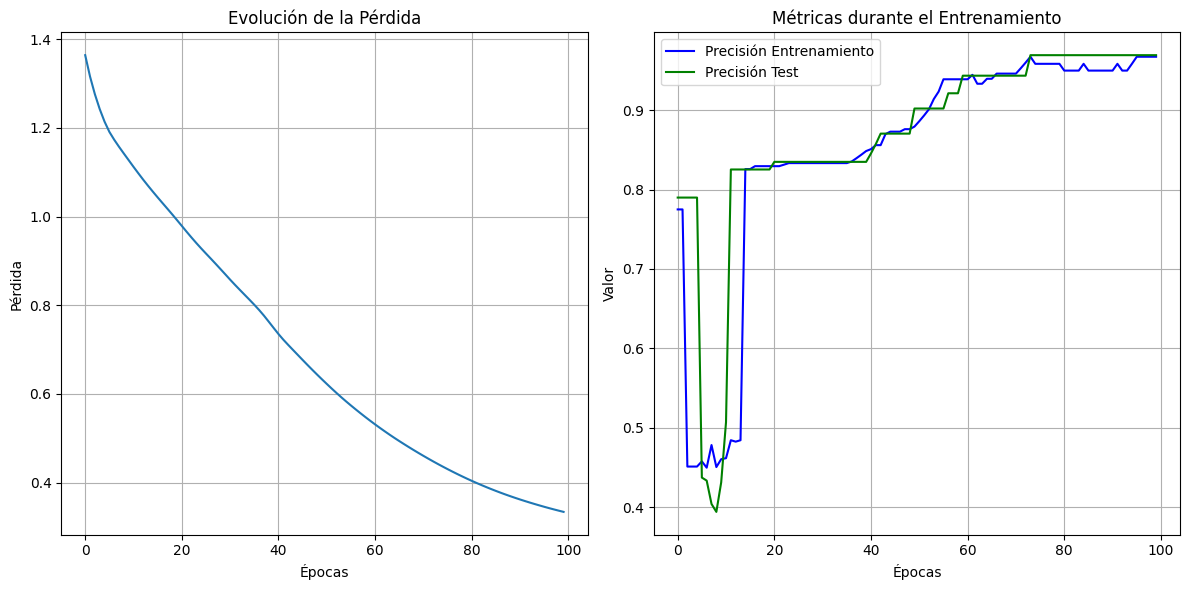

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

'''
# -------------------- ENTRADAS --------------------
# 6 muestras, 4 características
X_train = pd.DataFrame([
    [0.1, 0.2, 0.3, 0.4],
    [0.2, 0.1, 0.4, 0.3],
    [0.9, 0.8, 0.7, 0.6],
    [0.8, 0.9, 0.6, 0.7],
    [0.4, 0.3, 0.2, 0.1],
    [0.5, 0.6, 0.7, 0.8]
])

# -------------------- ETIQUETAS (multiclase) --------------------
# Clases: 0, 1 o 2
y_train = pd.Series([0, 0, 1, 1, 2, 2])
'''

# Entrenar el modelo
n_clases = 3
capas_ocultas = [10, 8]

# Entrenamos el modelo
#, recalls, f1_scores
modelo, perdidas, precisions_train, precisions_test = entrenar_red(
    X_train, y_train, n_clases=n_clases, capas_ocultas=capas_ocultas, X_test=X_test, y_test=y_test, epocas=100
)

# Predicciones de test
y_pred_test = predecir(X_test, modelo)

# Mostrar las predicciones
print("Predicciones:", y_pred_test)
print("Etiquetas reales:", y_test.to_numpy())

# Graficar las métricas
plt.figure(figsize=(12, 6))

# Graficar Pérdida
plt.subplot(1, 2, 1)
plt.plot(perdidas, label='Pérdida')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.title('Evolución de la Pérdida')
plt.grid(True)

# Graficar Precision, Recall, F1 y Precision de Entrenamiento
plt.subplot(1, 2, 2)
plt.plot(precisions_train, label='Precisión Entrenamiento', color='blue')
plt.plot(precisions_test, label='Precisión Test', color='green')
#plt.plot(recalls, label='Recall Test', color='orange')
#plt.plot(f1_scores, label='F1 Test', color='red')
plt.xlabel('Épocas')
plt.ylabel('Valor')
plt.title('Métricas durante el Entrenamiento')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
